In [69]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

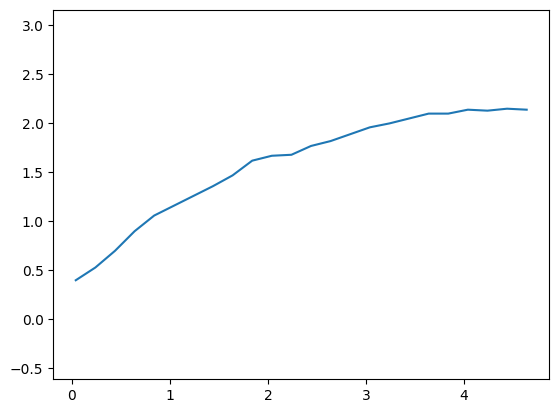

In [70]:
stylos = '''x,y
0.04,0.4
0.24,0.53
0.44,0.7
0.64,0.9
0.84,1.06
1.04,1.16
1.24,1.26
1.44,1.36
1.64,1.47
1.84,1.62
2.04,1.67
2.24,1.68
2.44,1.77
2.64,1.82
2.84,1.89
3.04,1.96
3.24,2
3.44,2.05
3.64,2.1
3.84,2.1
4.04,2.14
4.24,2.13
4.44,2.15
4.64,2.14'''.splitlines()
data = np.genfromtxt(stylos, delimiter=',', skip_header=1)

plt.figure()
plt.axis('equal')
plt.plot(data[:,0],data[:,1])
plt.show()

In [71]:
var_a = (np.log(2) / 1.96)**2
# posterior distribution
def posterior(theta, data):
  x = data[:,0][:,np.newaxis]
  y = data[:,1][:,np.newaxis]
  ln_a, b, var = theta
  n = data.shape[0]

  # support: 0 < beta < 1 and sigma^2 > 0
  in_support = (b > 0) & (b < 1) & (var > 0)
  # placeholder variance outside the support, so the sqrt below stays valid
  var = np.where(var > 0, var, 1.0)

  pi_ln_a = np.exp(-ln_a**2 / (2*var_a))
  pi_b = b**4 * (1-b)**4
  pi_var = 1/var

  L = np.prod(np.exp(-(np.log(y) - ln_a - b*np.log(x))**2 / (2*var)) / (y * np.sqrt(2*np.pi*var)), axis=0)

  return np.where(in_support, pi_ln_a * pi_b * pi_var * L, 0.0)

In [72]:
def sample_posterior_importance(data, g='prior', size=1000):
  match g:
    case 'prior':
      ln_a = scipy.stats.norm.rvs(scale=var_a, size=size)
      b = scipy.stats.beta.rvs(4, 4, size=size)
      var = scipy.stats.gamma.rvs(1, size=size)
      x = (ln_a, b, var)
      gx = (
          scipy.stats.norm.pdf(ln_a, scale=var_a),
          scipy.stats.beta.pdf(b, 4, 4),
          # gamma rather than improper 1/x
          scipy.stats.gamma.pdf(var, 1),
      )
      w = posterior(x, data) / gx
  return x, w

In [73]:
def beta_proposal_params(mode, var):
  # Beta(a, b) with the given mode and variance (requires var < 1/12).
  # With a = 1 + mode*k and b = 1 + (1-mode)*k, the mode is fixed for any k > 0.
  # Setting the variance to var gives a cubic in k with exactly one positive root.
  roots = np.roots([var, 7*var - mode*(1-mode), 16*var - 1, 12*var - 1])
  k = roots[np.isreal(roots) & (roots.real > 0)].real[0]
  return 1 + mode*k, 1 + (1-mode)*k

def sample_posterior_mh(data, proposal_dist='rw', size=1000):
  sample = np.empty((size, 3))
  u = scipy.stats.uniform.rvs(size=size)

  # initialise with prior means
  sample[0,:] = 0, 0.5, 0.01

  match proposal_dist:
    case 'rw':
      ln_a_step = 0.03     # sd of the Gaussian walk on ln(alpha)
      b_var = 0.0004       # variance of the Beta proposal for beta
      log_var_step = 0.46  # sd of the Gaussian walk on ln(sigma^2)

      # Density of proposing theta from given. The ln(alpha) walk is symmetric,
      # so its term cancels in the acceptance ratio and is left out.
      def q(theta, given):
        return (
            scipy.stats.beta.pdf(theta[1], *beta_proposal_params(given[1], b_var))
            * scipy.stats.lognorm.pdf(theta[2], s=log_var_step, scale=given[2])
        )

      def sample_q(t):
        ln_a, b, var = sample[t,:]
        return np.array([
            ln_a + scipy.stats.norm.rvs(scale=ln_a_step),
            scipy.stats.beta.rvs(*beta_proposal_params(b, b_var)),
            var * np.exp(scipy.stats.norm.rvs(scale=log_var_step)),
        ])

  for t in range(size-1):
      proposal = sample_q(t)
      ratio = (
          posterior(proposal, data) * q(sample[t,:], proposal)
          / (posterior(sample[t,:], data) * q(proposal, sample[t,:]))
      )
      accept_prob = min(ratio, 1.0)

      if u[t] < accept_prob:
        sample[t+1,:] = proposal
      else:
        sample[t+1,:] = sample[t,:]

  return sample

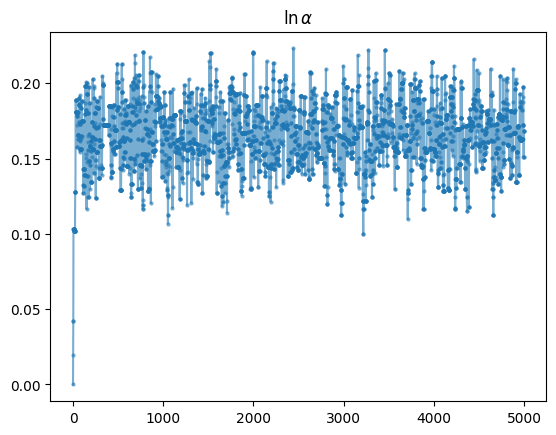

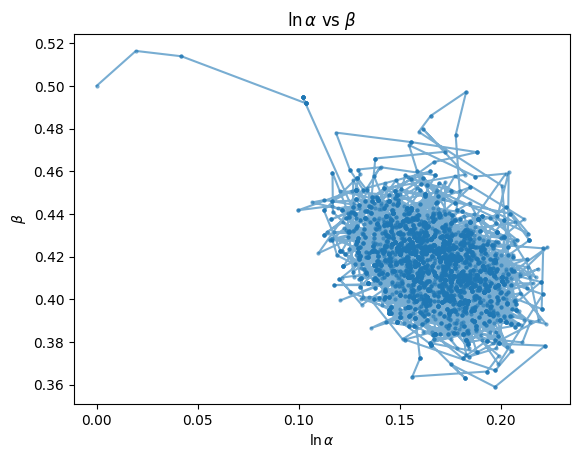

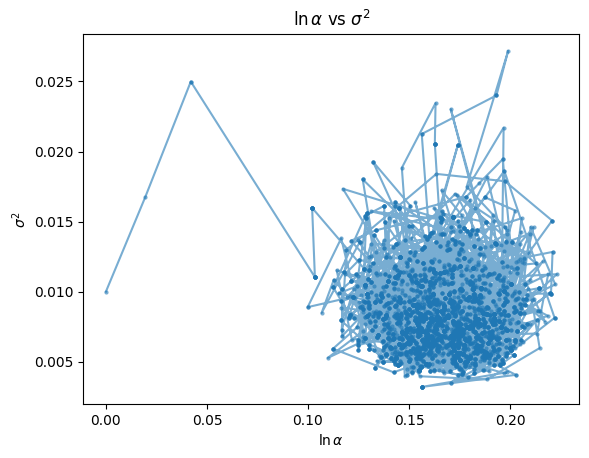

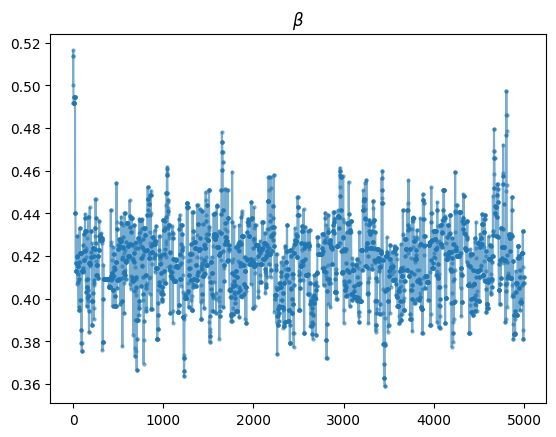

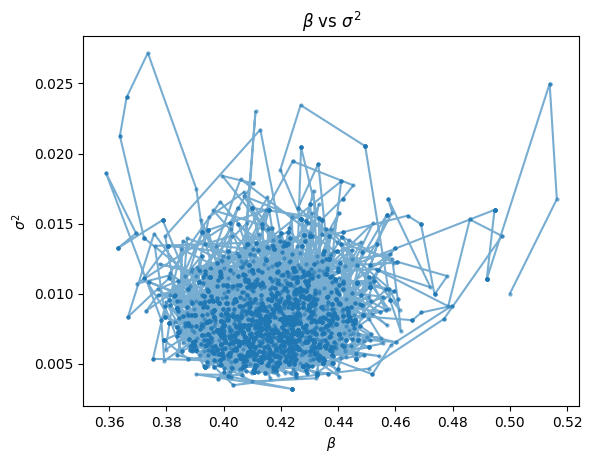

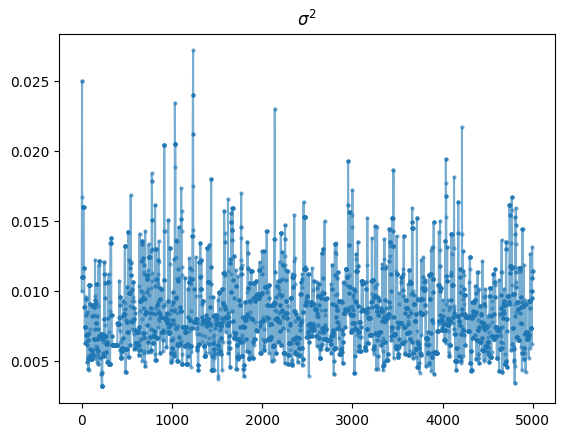

In [74]:
xs_samples = sample_posterior_mh(data, size=5000)
labels = ['$\\ln\\alpha$', '$\\beta$', '$\\sigma^2$']

# Transpose xs_samples to iterate over columns (each parameter's history of samples)
xs_cols = xs_samples.T

# Small, faint points and thin lines, so that 10,000 samples stay readable
plot_style = dict(markersize=3, markeredgewidth=0, linewidth=1.5, alpha=0.6)

for i, (label, x) in enumerate(zip(labels, xs_cols)):
  plt.plot(x, 'o-', **plot_style)
  plt.title(label)
  plt.show()

  # bivariates
  for j, (label2, x2) in enumerate(zip(labels[i+1:], xs_cols[i+1:])):
    plt.figure()
    plt.plot(x, x2, 'o-', **plot_style)
    plt.title(f'{label} vs {label2}')
    plt.xlabel(label)
    plt.ylabel(label2)
    plt.show()

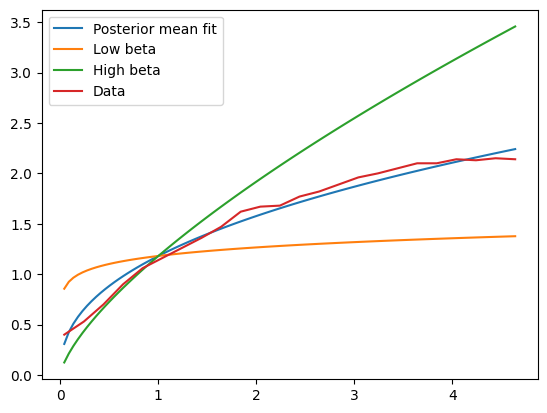

In [75]:
ln_a_pos_mean = np.mean(xs_samples[:,0])
b_pos_mean = np.mean(xs_samples[:,1])
def model(x, ln_a, b):
  return np.exp(ln_a + b*np.log(x))

x = np.linspace(data[:,0].min(), data[:,0].max(), 100)
plt.plot(x, model(x, ln_a_pos_mean, b_pos_mean), label='Posterior mean fit')
plt.plot(x, model(x, ln_a_pos_mean, 0.1), label='Low beta')
plt.plot(x, model(x, ln_a_pos_mean, 0.7), label='High beta')
plt.plot(data[:,0], data[:,1], label='Data')
plt.legend()

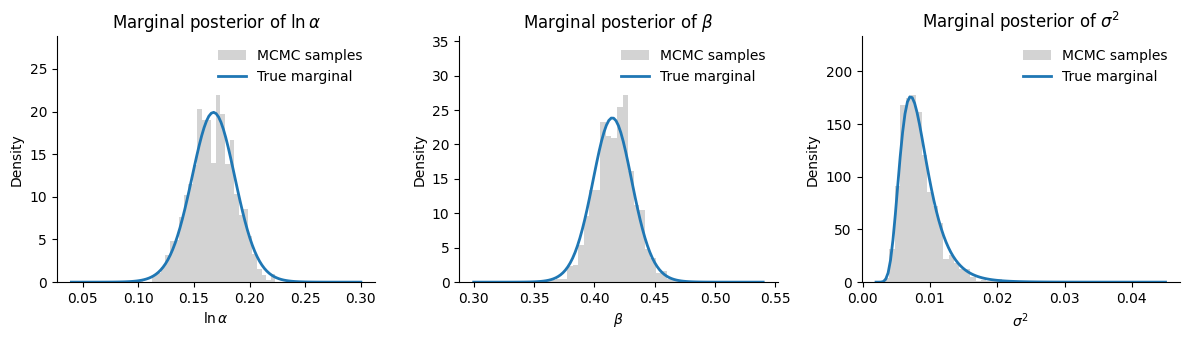

In [76]:
# True marginals: integrate the posterior numerically over the other two parameters.
# The grids must cover essentially all of the posterior mass.
ln_a_grid = np.linspace(0.04, 0.30, 121)
b_grid = np.linspace(0.30, 0.54, 121)
var_grid = np.linspace(0.002, 0.045, 121)

# Unnormalised posterior on the 3D grid, indexed as [ln_a, b, var]
B, V = np.meshgrid(b_grid, var_grid, indexing='ij')
density = np.empty((len(ln_a_grid), len(b_grid), len(var_grid)))
for i, ln_a in enumerate(ln_a_grid):
  density[i] = posterior((ln_a, B.ravel(), V.ravel()), data).reshape(B.shape)

trapezoid = scipy.integrate.trapezoid
ln_a_marginal = trapezoid(trapezoid(density, var_grid, axis=2), b_grid, axis=1)
b_marginal = trapezoid(trapezoid(density, var_grid, axis=2), ln_a_grid, axis=0)
var_marginal = trapezoid(trapezoid(density, b_grid, axis=1), ln_a_grid, axis=0)

grids = [ln_a_grid, b_grid, var_grid]
marginals = [ln_a_marginal, b_marginal, var_marginal]

# Iterations to discard while the chain moves away from its starting point
burn_in = 200

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for j, (ax, grid, marginal, label) in enumerate(zip(axes, grids, marginals, labels)):
  ax.hist(xs_samples[burn_in:, j], bins=30, density=True, color='lightgray', label='MCMC samples')
  # Normalise so that each marginal integrates to 1
  ax.plot(grid, marginal / trapezoid(marginal, grid), linewidth=2, label='True marginal')
  ax.set_title(f'Marginal posterior of {label}')
  ax.set_xlabel(label)
  ax.set_ylabel('Density')
  # Headroom so the legend clears the tallest bars
  ax.set_ylim(0, ax.get_ylim()[1] * 1.25)
  ax.spines[['top', 'right']].set_visible(False)
  ax.legend(frameon=False)

plt.tight_layout()
plt.show()